# Principles of visualization

Before any plotting library, three questions: **why** draw a chart at all, **which** chart answers which question, and how a correct chart can still **mislead**. The examples use the cleaned NileCart sales table (one row per order line, 2024–2025) and Plotly, the library used in the projects; the code is kept short here, and the [Plotly chapter](04_plotly.ipynb) explains it in full.

**Contents**
1. Why visualize?
2. Choosing the right chart
3. Reading charts correctly

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots

import plotly.io as pio

try:
    import kaleido  # noqa: F401  (also saves a static PNG of each chart, which GitHub can display)
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width = 900
except ImportError:
    pio.renderers.default = "plotly_mimetype+notebook"

pio.templates.default = "simple_white"
px.defaults.height = 380
TEAL, AMBER, CORAL, SLATE = "#0F766E", "#E89B2D", "#D95D4A", "#9AA5B1"

sales = pd.read_csv("../data/nilecart/sales.csv", parse_dates=["order_date"])
sales["year"] = sales["order_date"].dt.year
sales["month"] = sales["order_date"].dt.month
print(sales.shape)

(1466, 20)


---
## 1. Why visualize?

### 1.1 Same statistics, different stories

Monthly revenue in 2024 and 2025, summarised with the usual numbers:

In [2]:
monthly = sales.pivot_table(index="month", columns="year", values="revenue", aggfunc="sum")
(monthly.agg(["mean", "std", "median"]) / 1e6).round(2).rename(index=lambda s: s + " (M EGP)")

year,2024,2025
mean (M EGP),1.18,1.14
std (M EGP),0.59,0.56
median (M EGP),0.91,0.98


The two years look almost identical in the summary. The chart tells a different story:

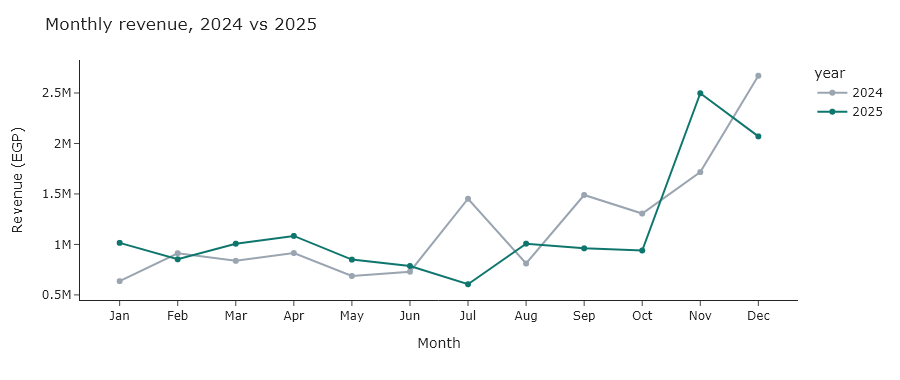

In [3]:
long = monthly.reset_index().melt(id_vars="month", var_name="year", value_name="revenue")
fig = px.line(long, x="month", y="revenue", color="year", markers=True,
              color_discrete_sequence=[SLATE, TEAL], labels={"revenue": "Revenue (EGP)", "month": "Month"})
fig.update_xaxes(tickvals=list(range(1, 13)), ticktext=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
fig.update_layout(title="Monthly revenue, 2024 vs 2025")

Similar mean and spread, but different years: 2024 has spikes in July and September and peaks in December, while 2025 stays flat until a November peak. Summary numbers compress a column into one value each; a chart keeps the **pattern**: trends, seasonality, clusters, outliers and errors.

### 1.2 Explore or explain?

| | Explore (for yourself) | Explain (for others) |
|---|---|---|
| How many | many quick charts, rough is fine | one chart per message, polished |
| Goal | find patterns, errors, new questions | the reader gets the point in five seconds |
| Title | says what is plotted: "Revenue by month" | says what it means: "Nov–Dec bring a third of the revenue" |

Exploratory data analysis (EDA) is mostly exploring; a report or a dashboard is explaining.

### 1.3 Number, table or chart?

- **A number** for one fact: "the median order line is worth 3,820 EGP".
- **A table** for exact values to look up: the price list, one customer's orders.
- **A chart** for a pattern, a shape, a comparison or an outlier.

If one sentence says it, a chart is not needed.

---
## 2. Choosing the right chart

### 2.1 Start from the variable types

| Type | Example in `sales` | Typical encoding |
|---|---|---|
| Numerical, continuous | `revenue`, `profit` | position on a scale (x / y) |
| Numerical, discrete | `quantity` | position, or one bar per value |
| Categorical, nominal | `category`, `region` | separate bars, colour hue |
| Categorical, ordinal | discount level 0 / 5 / 10 / 20% | bars or a line, kept in order |
| Time | `order_date`, month | x-axis from left to right, usually a line |

⚠️ An ordinal or time axis is never sorted by value: the order is part of the data.

### 2.2 Position and length beat angle and colour

People compare **positions** on a common scale and **lengths** precisely; angles, areas and colour shades much less so. The same five numbers as a bar chart and as a pie:

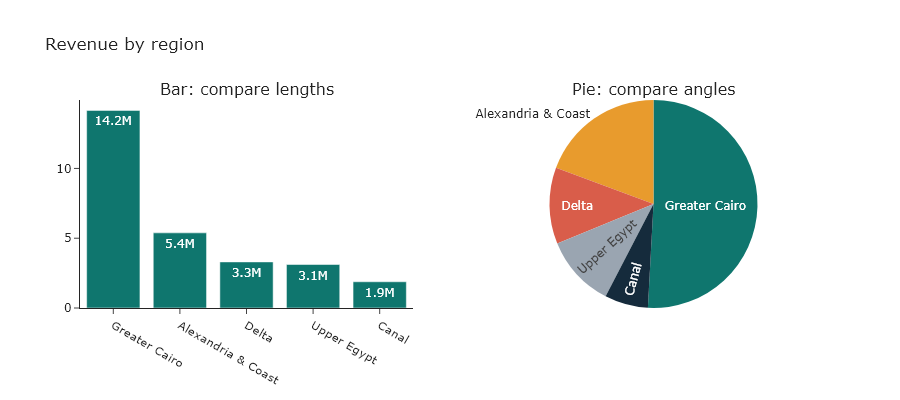

In [4]:
reg = (sales[sales["region"] != "Unknown"].groupby("region", as_index=False)["revenue"].sum()
       .sort_values("revenue", ascending=False))

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "xy"}, {"type": "domain"}]],
                    subplot_titles=["Bar: compare lengths", "Pie: compare angles"])
fig.add_bar(x=reg["region"], y=reg["revenue"] / 1e6, marker_color=TEAL, texttemplate="%{y:.1f}M", row=1, col=1)
fig.add_pie(labels=reg["region"], values=reg["revenue"], textinfo="label", sort=False,
            marker_colors=[TEAL, AMBER, CORAL, SLATE, "#152B3C"], row=1, col=2)
fig.update_layout(showlegend=False, height=400, title="Revenue by region")

On the pie, Delta and Upper Egypt look the same size; on the bars, Delta is clearly ahead (3.3M vs 3.1M EGP), and the ranking reads at a glance. From most to least precise: **position → length → angle / area → colour shade → colour hue**. A pie is acceptable only for a few parts (at most about five) of one whole, when rough shares are enough.

### 2.3 The chart selection table

| Chart | Best used for | What to read |
|---|---|---|
| Bar chart | comparing categories | differences, ranking |
| Line chart | trends over time or an ordered sequence | direction, change, seasonality |
| Histogram | the distribution of one number | shape, spread, skew |
| Scatter plot | the relationship of two numbers | association, clusters, odd points |
| Box plot | comparing distributions | median, quartiles, outliers |
| Violin plot | comparing distribution shapes | density, several peaks |
| Count plot | the frequency of categories | most and least common |
| Stacked bar | the composition of categories | totals and their parts |
| Heatmap | values across two dimensions | hot spots, patterns |
| Pair plot | several numeric variables | every pairwise relationship |
| Pie chart | a few parts of one whole | rough proportions (≤ 5 slices) |

The same question with different variables can need a different chart: *"how does revenue differ by category?"* is a bar chart of a total, but a box plot when the question is about the spread of single orders.

### 2.4 Anatomy of an honest chart

1. a **title** that states the message,
2. **axis labels** with the unit (EGP, %, count),
3. a **scale** that starts at 0 for bars, with readable ticks,
4. a **legend** only when there are several series,
5. an **annotation** pointing at the one thing to notice,
6. a **source or note** saying where the data came from.

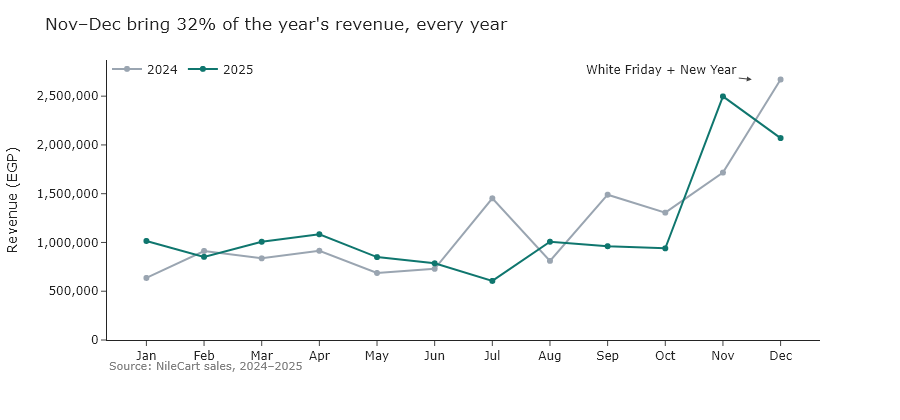

In [5]:
nov_dec = monthly.loc[[11, 12]].sum() / monthly.sum()
fig = px.line(long, x="month", y="revenue", color="year", markers=True, color_discrete_sequence=[SLATE, TEAL],
              labels={"revenue": "Revenue (EGP)", "month": "", "year": ""})
fig.update_xaxes(tickvals=list(range(1, 13)), ticktext=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
fig.update_yaxes(rangemode="tozero", tickformat=",")
fig.add_annotation(x=11.5, y=monthly.loc[11:12].max().max(), text="White Friday + New Year",
                   showarrow=True, arrowhead=2, ax=-90, ay=-10)
fig.update_layout(title=f"Nov–Dec bring {nov_dec.mean():.0%} of the year's revenue, every year", height=420,
                  legend=dict(orientation="h", y=1.02, x=0))
fig.add_annotation(text="Source: NileCart sales, 2024–2025", xref="paper", yref="paper", x=0, y=-0.12,
                   showarrow=False, font_size=11, font_color="gray")

---
## 3. Reading charts correctly

A chart can be computed correctly and still mislead. Five common traps:

### 3.1 Bars must start at 0

A bar encodes its value by its **length**. Cut the axis and the lengths lie:

Small Business vs Consumer: real difference 4%, bar length 146% longer on the left chart


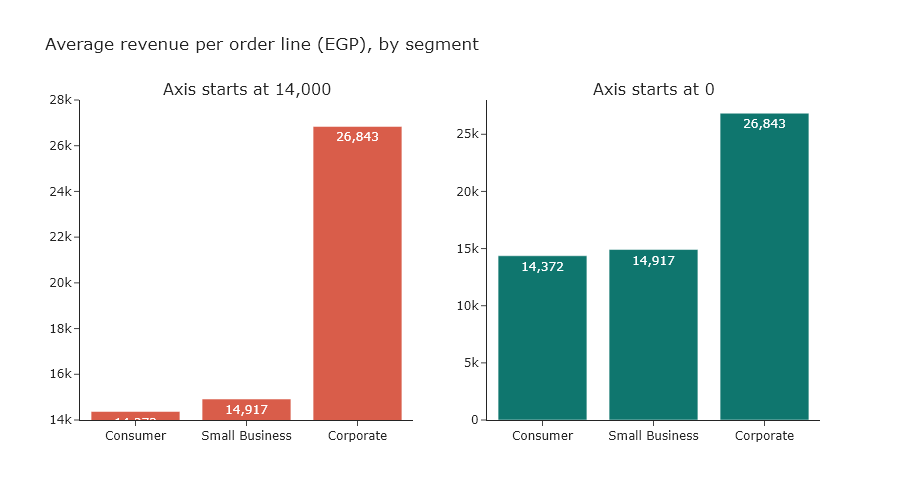

In [6]:
aov = (sales[sales["segment"] != "Unknown"].groupby("segment", as_index=False)["revenue"].mean()
       .sort_values("revenue"))
LOW = 14_000                                  # where the misleading axis starts
fig = make_subplots(rows=1, cols=2, subplot_titles=[f"Axis starts at {LOW:,}", "Axis starts at 0"])
fig.add_bar(x=aov["segment"], y=aov["revenue"], marker_color=CORAL, texttemplate="%{y:,.0f}", row=1, col=1)
fig.add_bar(x=aov["segment"], y=aov["revenue"], marker_color=TEAL, texttemplate="%{y:,.0f}", row=1, col=2)
fig.update_yaxes(range=[LOW, 28_000], row=1, col=1).update_yaxes(range=[0, 28_000], row=1, col=2)
fig.update_layout(showlegend=False, title="Average revenue per order line (EGP), by segment")

a = aov.set_index("segment")["revenue"]
print(f"Small Business vs Consumer: real difference {a['Small Business'] / a['Consumer'] - 1:.0%}, "
      f"bar length {(a['Small Business'] - LOW) / (a['Consumer'] - LOW) - 1:.0%} longer on the left chart")
fig

A line chart may zoom in (it encodes by position, not length), but the axis should then be clearly labelled.

### 3.2 Counts or rates?

Bigger groups have more of everything. To compare groups of different sizes, divide by the size:

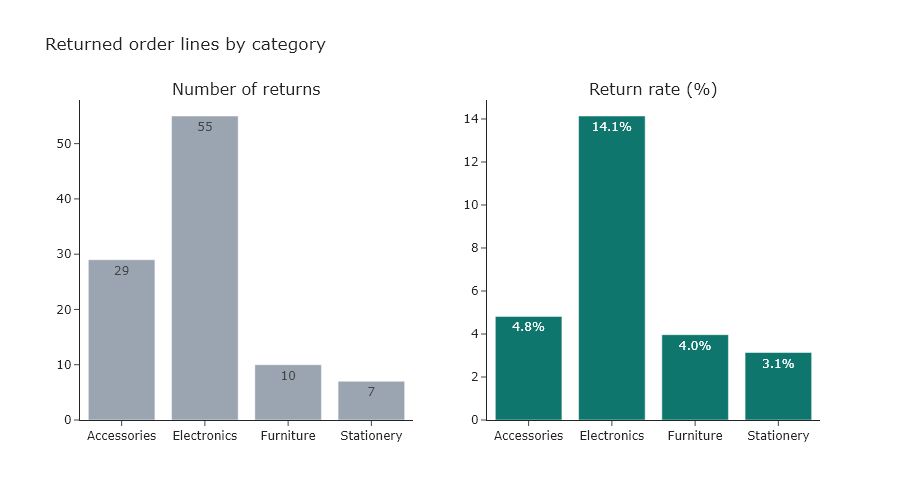

In [7]:
ret = (sales.assign(returned=sales["status"].eq("returned"))
            .groupby("category")["returned"].agg(count="sum", rate="mean").reset_index())
ret["rate"] = ret["rate"] * 100

fig = make_subplots(rows=1, cols=2, subplot_titles=["Number of returns", "Return rate (%)"])
fig.add_bar(x=ret["category"], y=ret["count"], marker_color=SLATE, texttemplate="%{y}", row=1, col=1)
fig.add_bar(x=ret["category"], y=ret["rate"], marker_color=TEAL, texttemplate="%{y:.1f}%", row=1, col=2)
fig.update_layout(showlegend=False, title="Returned order lines by category")
fig

In [8]:
ret.set_index("category").round(1)

,count,rate
category,,
Accessories,29,4.8
Electronics,55,14.1
Furniture,10,4.0
Stationery,7,3.1


Accessories have almost three times as many returns as Furniture (29 vs 10), yet the two rates are close (4.8% vs 4.0%): Accessories simply sell more. The rate is what shows the real problem, Electronics, where one order line in seven comes back.

### 3.3 Average or median?

On a skewed column the mean and the median tell different stories, and a chart should say which one it shows:

mean 18,991 | median 3,820 | skew 3.6


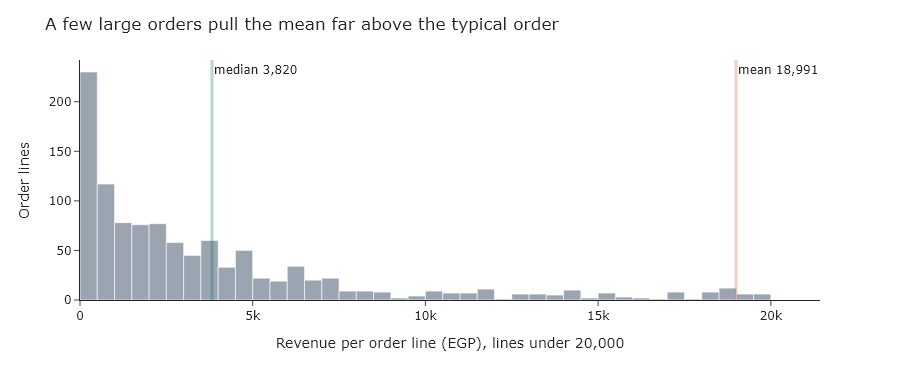

In [9]:
mean, median = sales["revenue"].mean(), sales["revenue"].median()
print(f"mean {mean:,.0f} | median {median:,.0f} | skew {sales['revenue'].skew():.1f}")

fig = px.histogram(sales[sales["revenue"] < 20000], x="revenue", nbins=60, color_discrete_sequence=[SLATE],
                   labels={"revenue": "Revenue per order line (EGP), lines under 20,000"})
fig.add_vline(median, line_color=TEAL, line_width=3, annotation_text=f"median {median:,.0f}")
fig.add_vline(mean, line_color=CORAL, line_width=3, annotation_text=f"mean {mean:,.0f}")
fig.update_layout(title="A few large orders pull the mean far above the typical order", yaxis_title="Order lines")

For skewed data, report the median, or show the whole distribution. The same applies to *count* vs *%* vs *average*: an axis label always says which one.

### 3.4 Who is missing, and how many are there?

- **Sampling bias:** the sales table only holds people who bought. Customers who never ordered, or left after one bad experience, are invisible. The question to ask is *who could not end up in this data?*
- **Tiny groups:** a rate or an average from a handful of rows is noise. Show the group size next to it, or leave the group out:

In [10]:
sales.groupby("segment")["revenue"].agg(order_lines="size", mean_revenue="mean").round(0)

,order_lines,mean_revenue
segment,,
Consumer,762,14372.0
Corporate,538,26843.0
Small Business,164,14917.0
Unknown,2,902.0


The *Unknown* segment (the orders whose customer is missing) has only a couple of rows; its average says nothing.

### 3.5 Before trusting a chart

1. **Axis:** does a bar axis start at 0? Is it linear or log?
2. **Measure:** count, %, mean or median? Per what?
3. **Shape:** would other bins or a log scale change the story?
4. **Groups:** are some groups tiny? Who is missing?
5. **Cause:** could a third factor explain the pattern? (A correlation between two columns can come from a third one, or reverse inside groups; the [Seaborn chapter](03_seaborn.ipynb) shows an example.)

---
**Next:** [Matplotlib](02_matplotlib.ipynb), the library under most Python charts.